# Europarl scaled v3: exploratory data analysis

This notebook reads the frozen document-stratified Europarl scaled v3 split and saved EDA outputs. No model is trained here. This is the controlled scaled v3 subset: 12,000 train, 1,500 validation and 1,500 test pairs across distinct documents. The smaller v2 and pilot results are not loaded here.


In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data/processed/europarl_scaled_v3').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA = PROJECT_ROOT / 'data/processed/europarl_scaled_v3'
METRICS = PROJECT_ROOT / 'outputs/metrics/europarl_scaled_v3'
FIGURES = PROJECT_ROOT / 'outputs/figures/eda_scaled_v3'
assert DATA.is_dir(), f'Missing {DATA}'
manifest = json.loads((DATA / 'summary.json').read_text(encoding='utf-8'))
frames = []
for split in ('train', 'validation', 'test'):
    path = DATA / f'{split}.csv'
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == manifest['csv_sha256'][split], f'Hash mismatch: {path}'
    frame = pd.read_csv(path, dtype={'src_sent_id': str, 'tgt_sent_id': str})
    assert frame['split'].eq(split).all()
    frames.append(frame)
data = pd.concat(frames, ignore_index=True)
print('Verified dataset SHA256 for train, validation and test.')


Verified dataset SHA256 for train, validation and test.


## Split size and document coverage

Splits are grouped by English source document. Inspect document counts as well as sentence counts; many sentences from one document do not represent independent documents.


In [2]:
counts = data.groupby(['split', 'pair']).agg(
    sentences=('src', 'size'), documents=('doc_id', 'nunique')
).reset_index()
display(counts)
docs = {split: set(data.loc[data.split == split, 'doc_id'])
        for split in ('train', 'validation', 'test')}
for left, right in (('train', 'validation'), ('train', 'test'), ('validation', 'test')):
    assert not (docs[left] & docs[right]), f'Document leakage: {left}/{right}'
print('Split document counts:', {k: len(v) for k, v in docs.items()})
print('Document-disjoint splits: PASS')


,split,pair,sentences,documents
0,test,en-de,1000,100
1,test,en-fr,500,100
2,train,en-de,8000,400
3,train,en-fr,4000,400
4,validation,en-de,1000,100
5,validation,en-fr,500,100


Split document counts: {'train': 400, 'validation': 100, 'test': 100}
Document-disjoint splits: PASS


## Length and truncation

The model translates the current English source sentence. The context configuration appends the preceding English sentence as `src </s> previous_src` and truncates the source on the right at 128 mBART tokens. These tables were generated separately from the v3 dataset.


In [3]:
for filename in ('eda_length_summary.csv', 'eda_truncation_summary.csv',
                 'eda_longest_context_examples.csv'):
    path = METRICS / filename
    if path.exists():
        table = pd.read_csv(path)
        print(filename, len(table), 'rows')
        if filename == 'eda_length_summary.csv':
            display(table[(table['split'] == 'all') & (table['pair'] == 'all')])
        elif filename == 'eda_truncation_summary.csv':
            display(table[(table['split'] == 'all') & (table['pair'] == 'all')])
        else:
            display(table.head(5))
    else:
        print('Pending saved EDA table:', path)


eda_length_summary.csv 84 rows


,split,pair,measure,count,mean,std,min,p50,p90,p95,p99,max
0,all,all,previous_src_words,15000,23.273933,12.582400,1,21.0,40.0,47.0,63.0,109
1,all,all,src_words,15000,22.628600,12.034946,2,21.0,39.0,45.0,60.0,84
2,all,all,tgt_words,15000,22.105667,11.945114,2,20.0,38.0,45.0,60.0,89
3,all,all,previous_src_tokens,15000,32.085600,16.107173,4,29.0,53.0,62.0,83.0,143
4,all,all,src_tokens,15000,30.955267,15.320304,5,28.0,51.0,59.0,80.0,120
5,all,all,tgt_tokens,15000,35.458467,18.222448,5,32.0,59.0,70.0,92.0,141
6,all,all,context_src_tokens,15000,63.040867,23.256014,10,60.0,94.0,106.0,132.0,203


eda_truncation_summary.csv 48 rows


,split,pair,input_type,max_length,num_examples,num_truncated,truncated_percent
0,all,all,sentence,128,15000,0,0.00
1,all,all,sentence,256,15000,0,0.00
2,all,all,context,128,15000,177,1.18
3,all,all,context,256,15000,0,0.00


eda_longest_context_examples.csv 20 rows


,pair,split,doc_id,previous_src,src,tgt,previous_src_tokens,src_tokens,tgt_tokens,context_src_tokens
0,en-de,validation,en/ep-08-03-26-004.xml,Given the current disruption in the financial ...,"Finally, given the current chaos in the moneta...",Schließlich kann ich mir angesichts des gegenw...,108,95,97,203
1,en-fr,validation,en/ep-96-12-13.xml,"In the same spirit, we have proposed that no d...",The reason for this is the obligation to make ...,Ce report s'explique par l'obligation de tenir...,97,100,106,197
2,en-de,validation,en/ep-96-12-13.xml,"In the same spirit, we have proposed that no d...",The reason for this is the obligation to make ...,Erforderlich wird diese Verschiebung zum einen...,97,100,102,197
3,en-de,train,en/ep-10-10-21-008.xml,With this in mind I believe that the Commissio...,"To this end, I believe that the Commission sho...",Zu diesem Zweck sollte die Kommission meiner M...,143,39,46,182
4,en-de,test,en/ep-09-09-17-005.xml,I voted in favour of the European Parliament r...,"According to the European Union's principles, ...",Nach den Grundsätzen der Europäischen Union so...,108,71,74,179


## Figures

Saved plots correspond to the multidoc v3 dataset and should not be mixed with v2 or pilot figures.


01_pair_counts.png


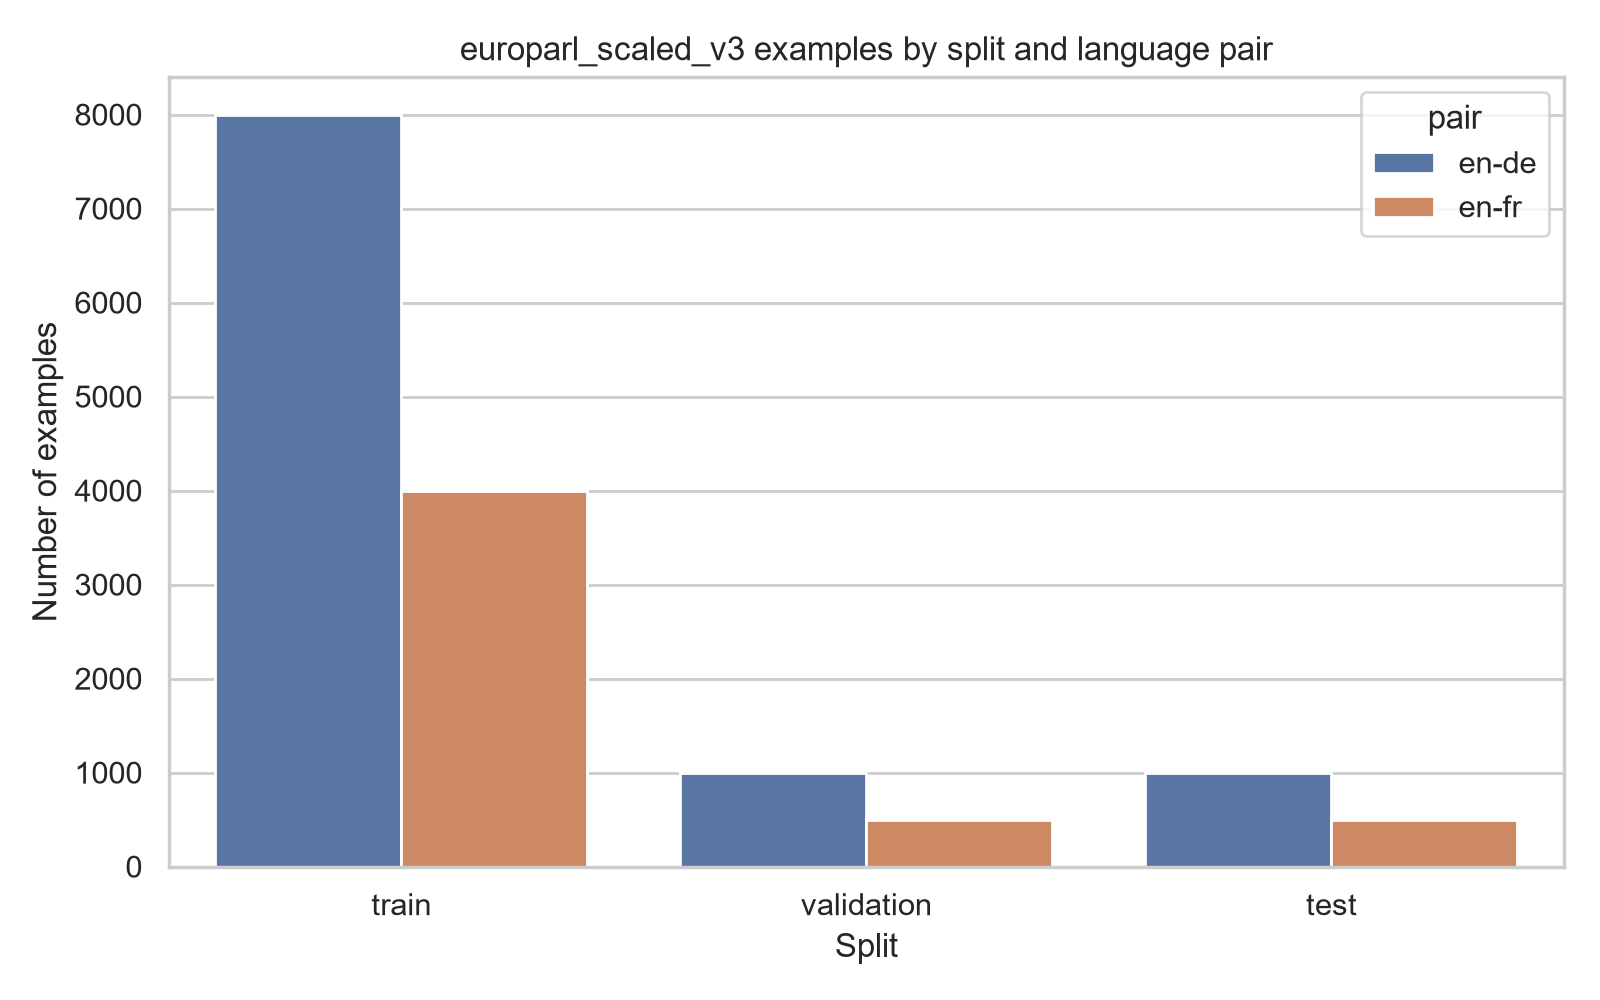

02_token_length_distributions.png


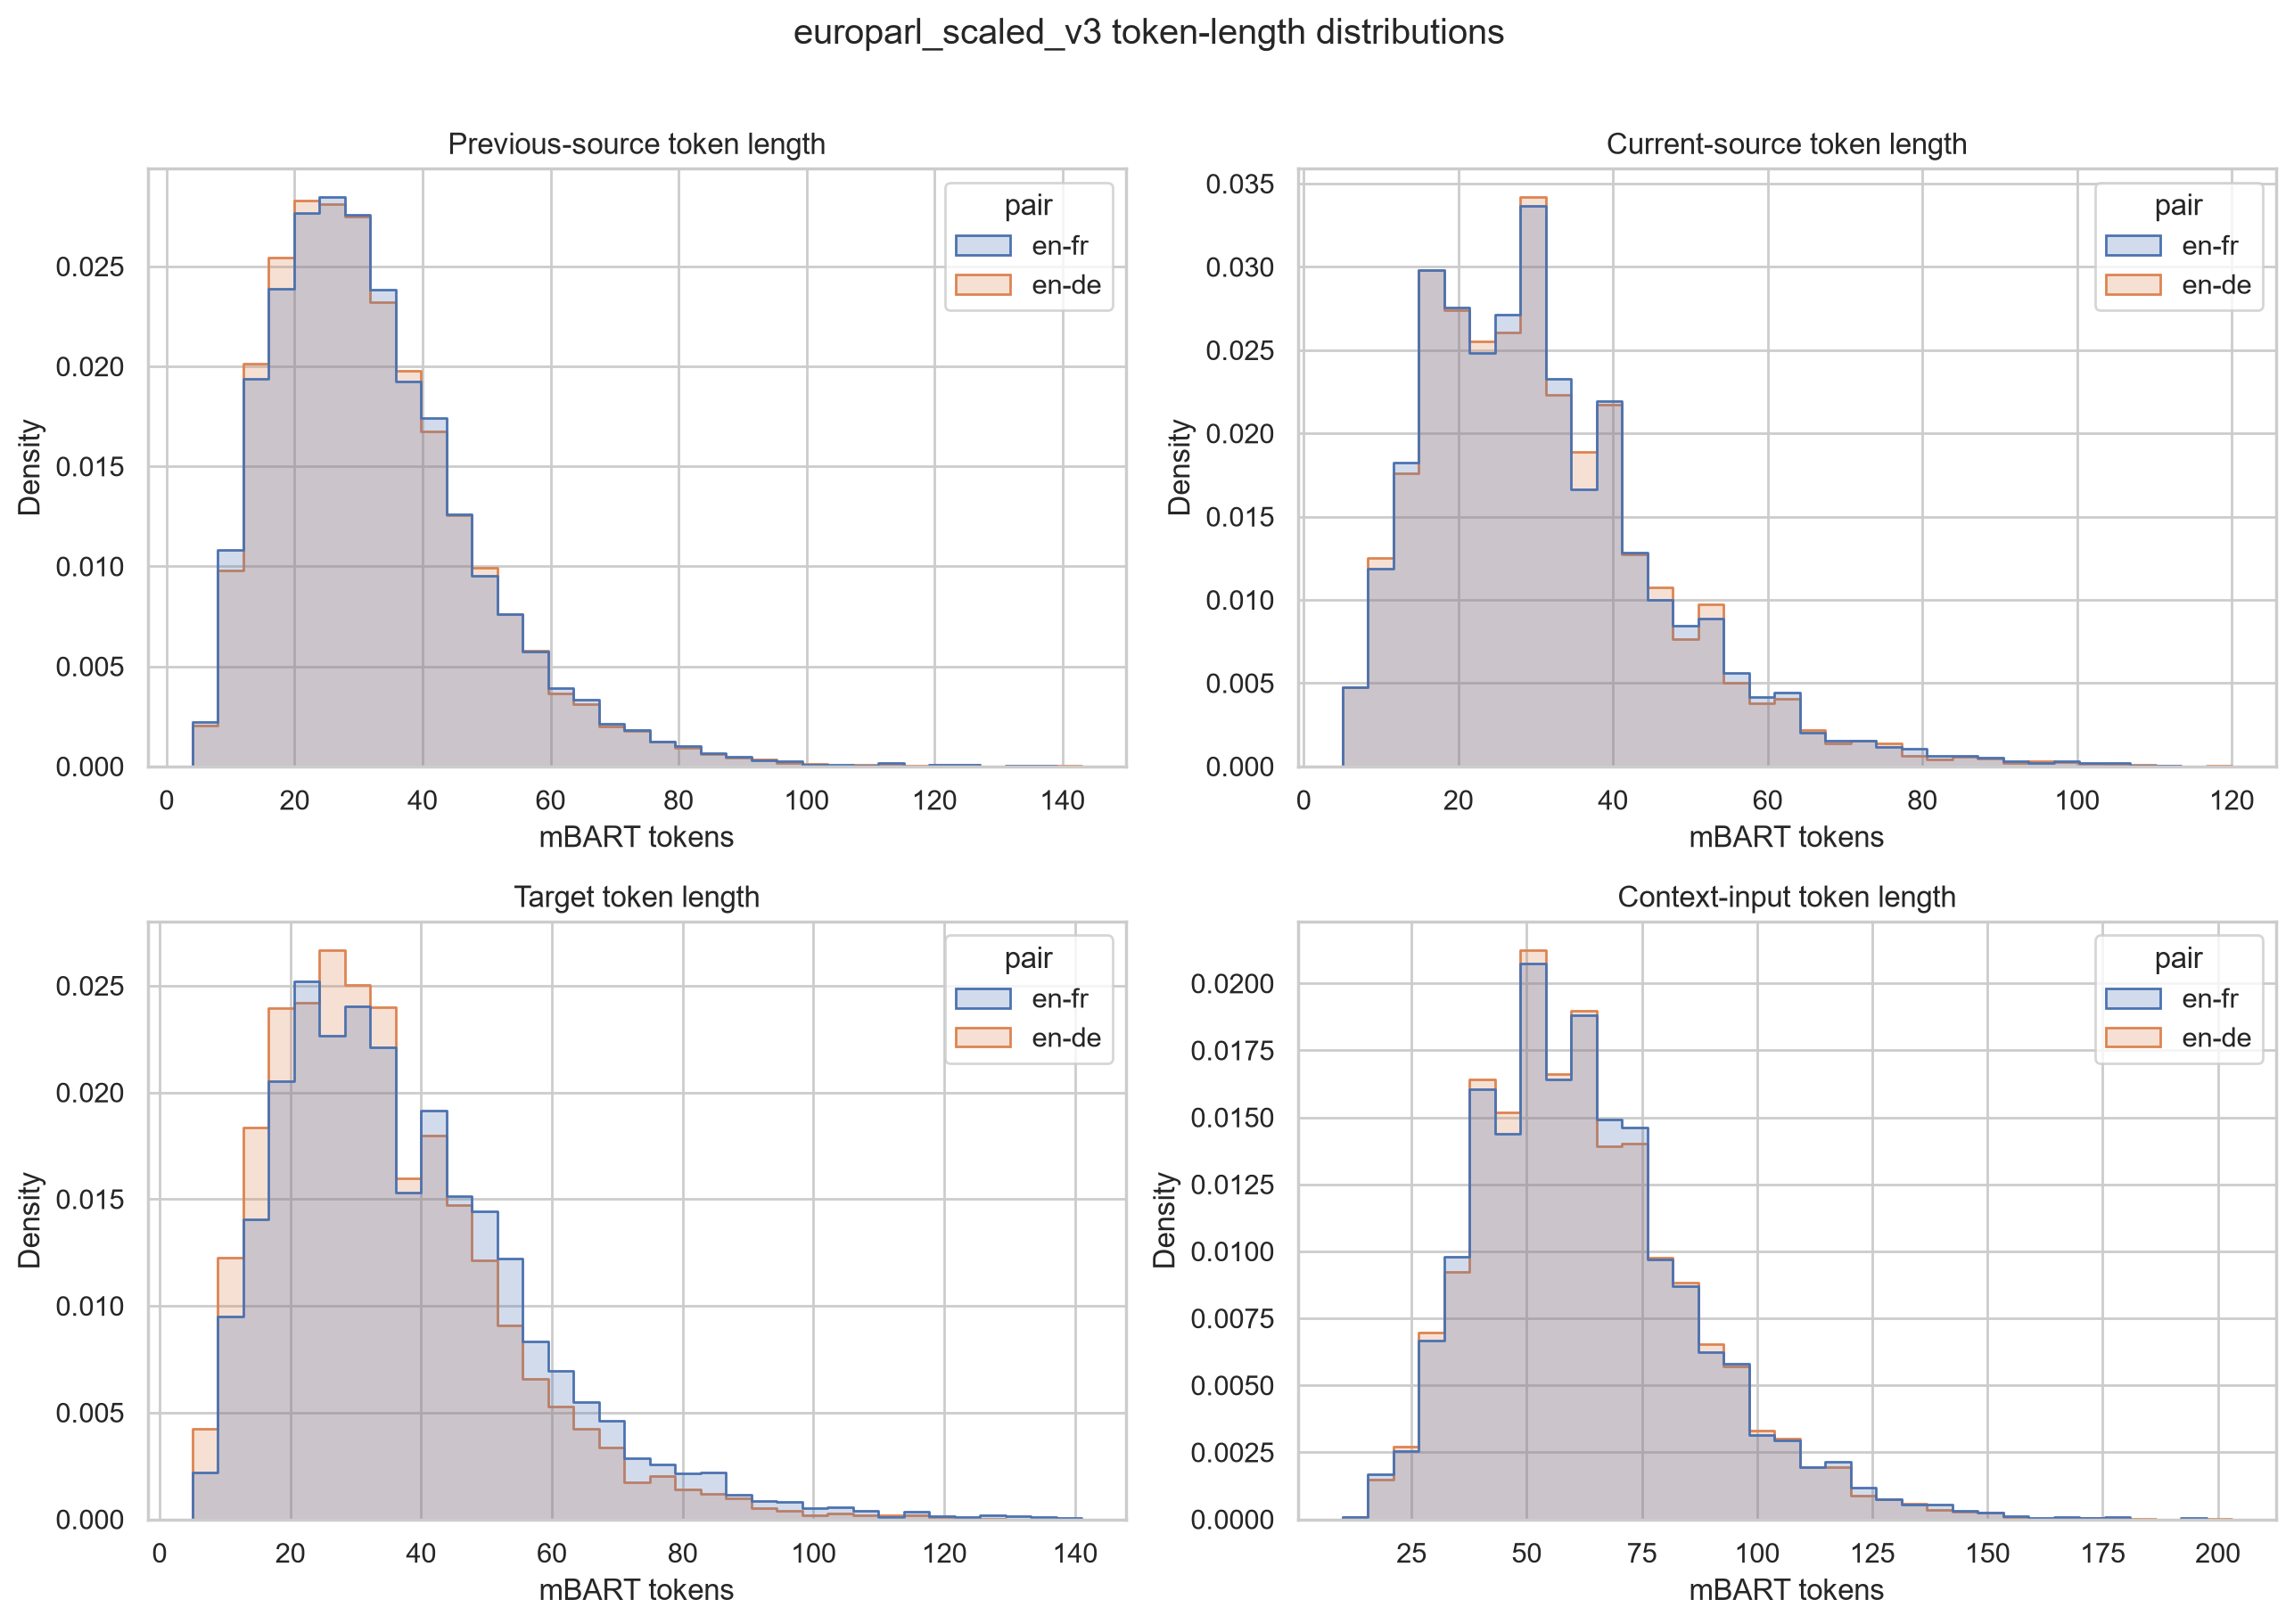

03_context_length_boxplot.png


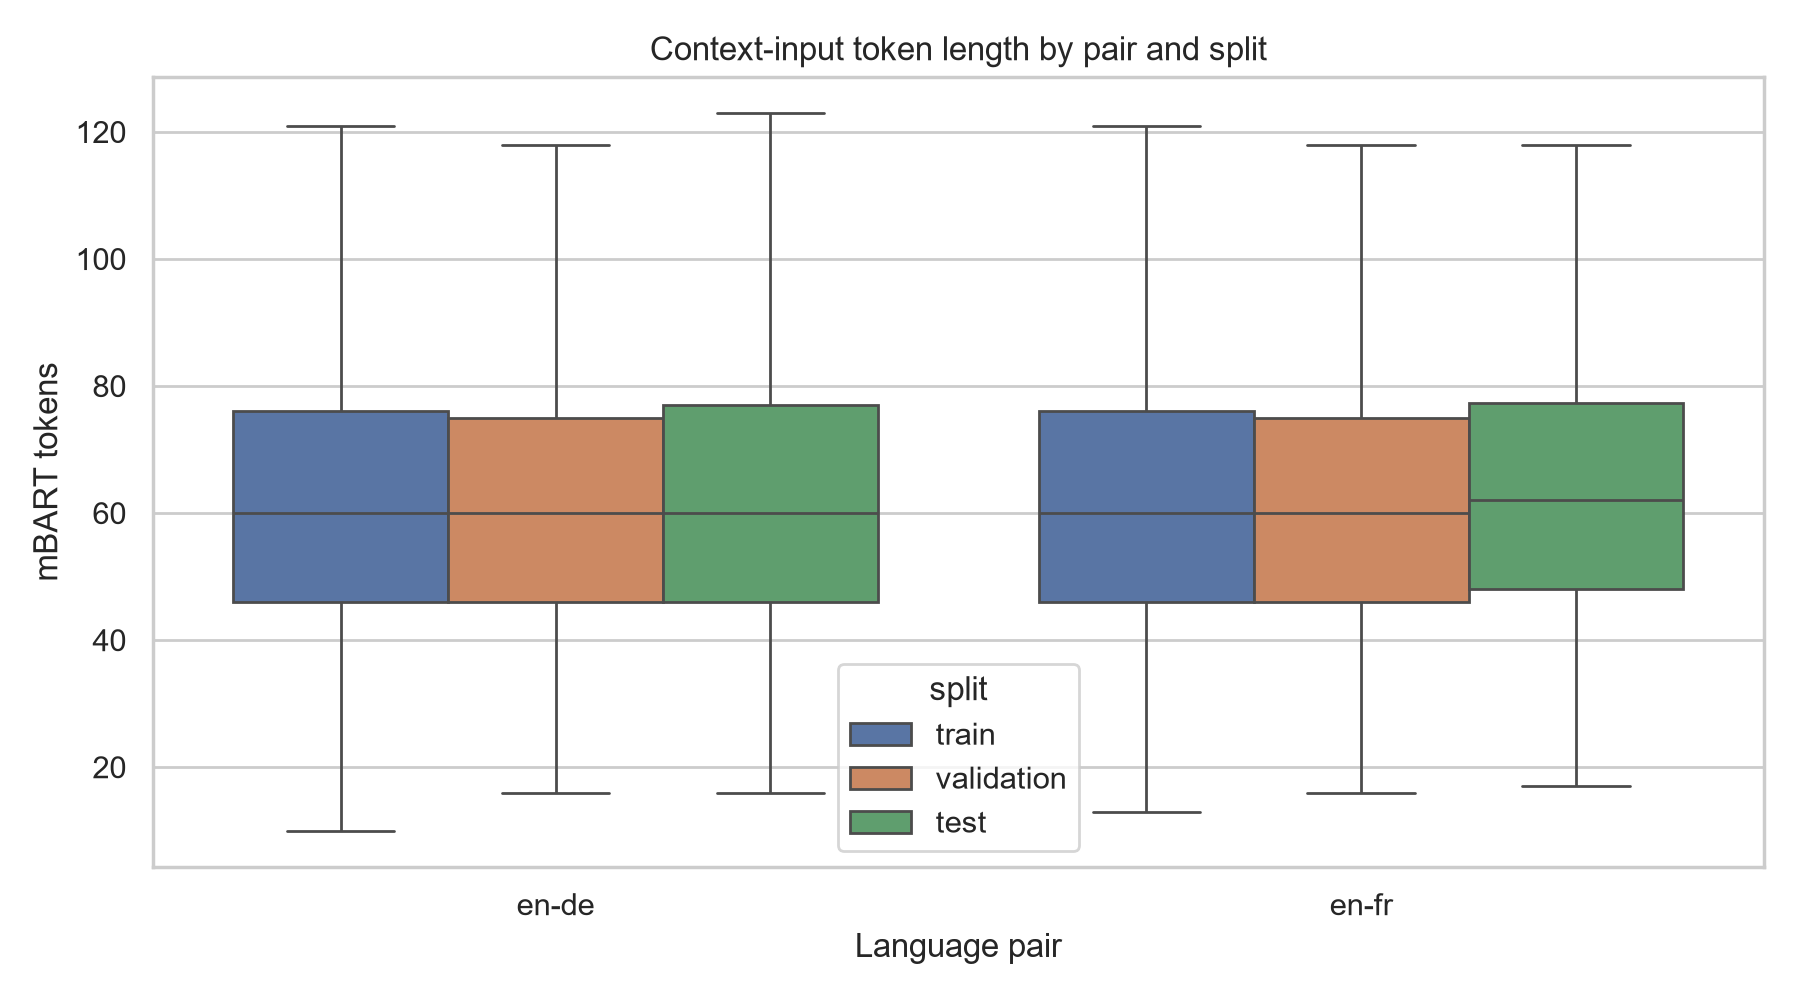

04_source_target_tokens.png


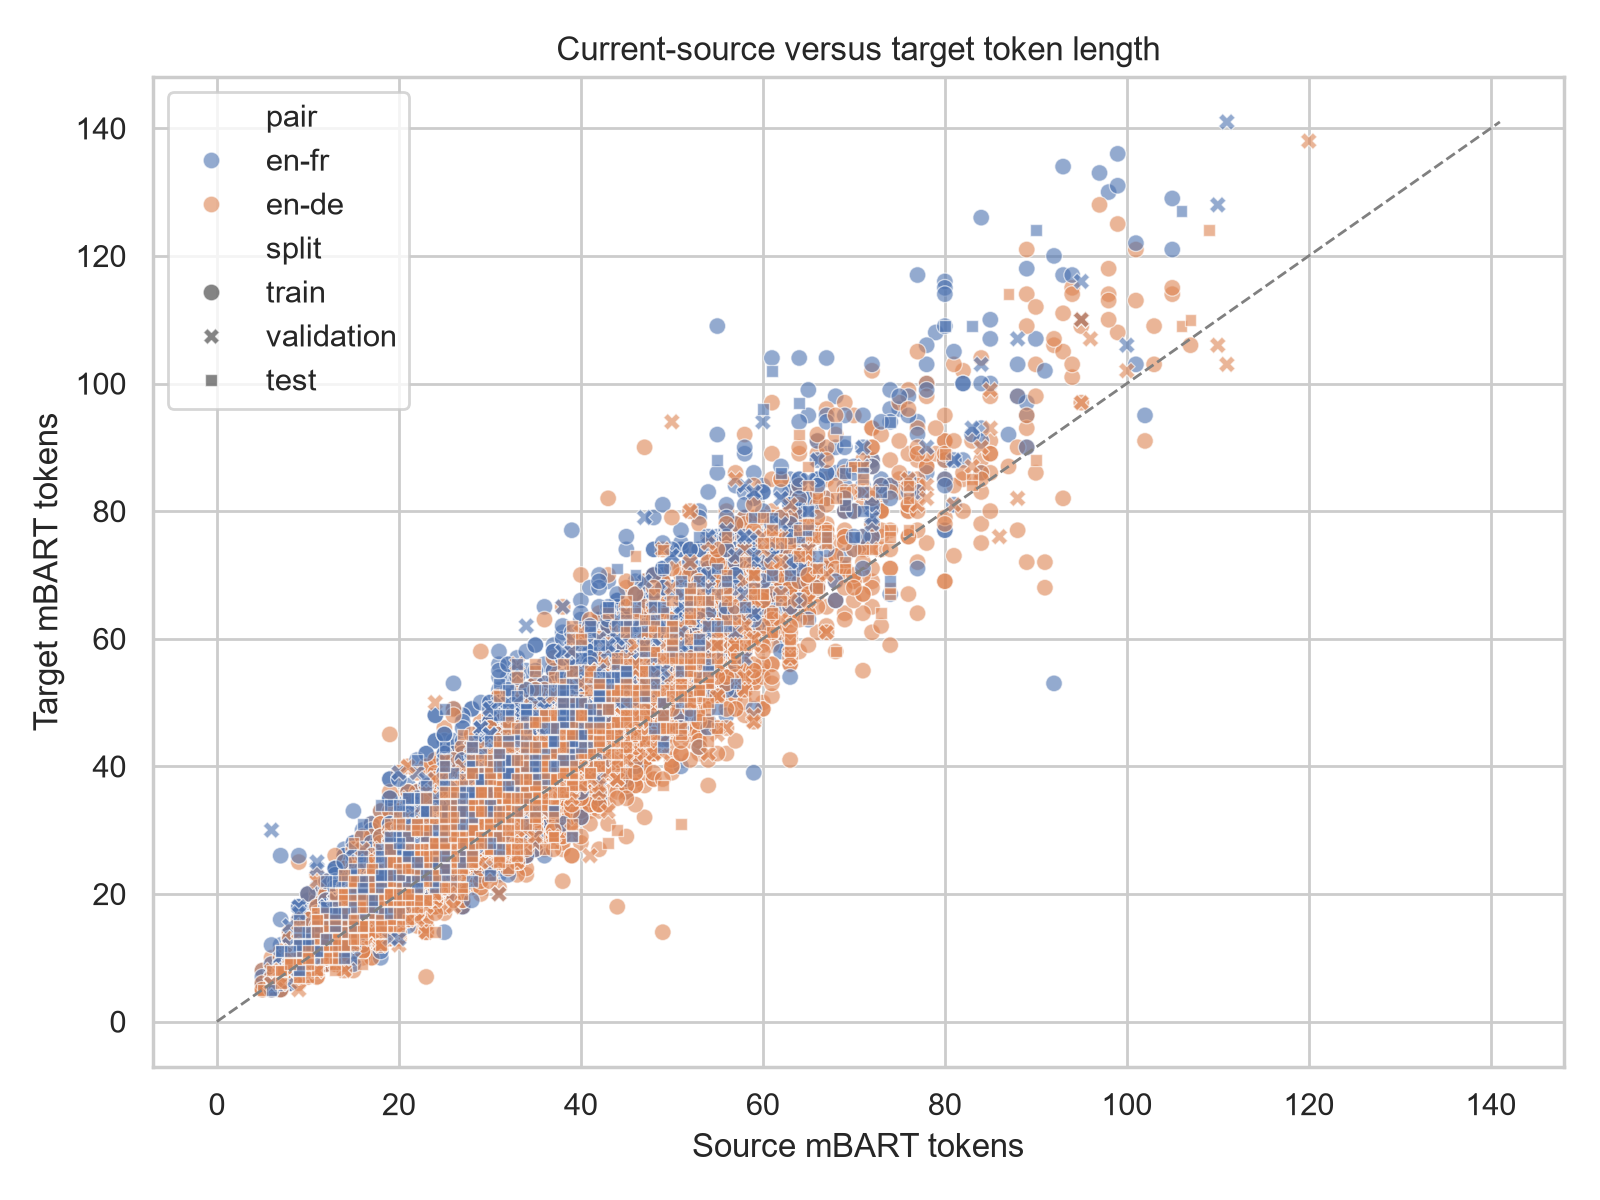

05_context_truncation_rate.png


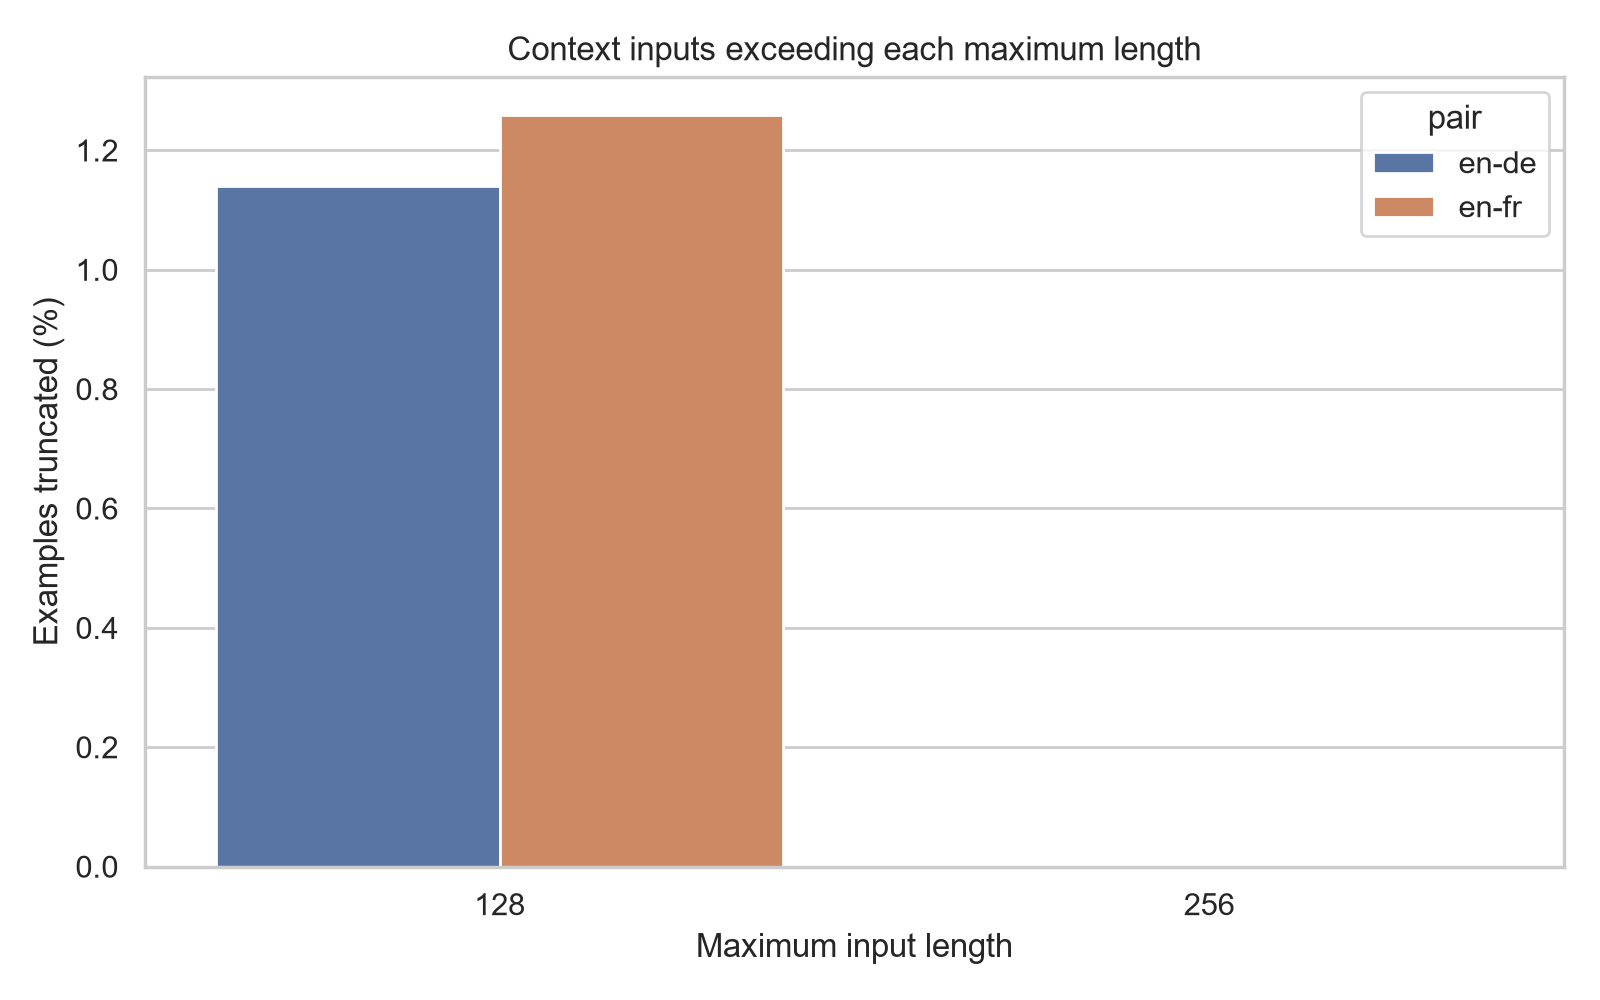

In [4]:
for filename in ('01_pair_counts.png', '02_token_length_distributions.png',
                 '03_context_length_boxplot.png', '04_source_target_tokens.png',
                 '05_context_truncation_rate.png'):
    path = FIGURES / filename
    print(filename)
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print('Pending saved figure:', path)


## Modeling note

The 8,000/4,000 English–German/English–French training split motivates pair-balanced loss. The split contains 400 train documents, 100 validation documents and 100 held-out test documents. Analyses that compare systems should report language-pair scores and treat document clustering as a limitation.
